# India Air Quality Analysis (2022–2026)

## Project Overview

This project explores air pollution patterns across selected Indian cities using publicly available air quality data from data.gov.in.

The objective is to analyse maximum AQI values, identify highly polluted cities, compare AQI patterns across years and months, and classify observations according to India's AQI categories.

## Tools and Technologies
- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## Dataset Information
- Source: data.gov.in
- Original records: 160
- Valid records after cleaning: 154
- Cities covered: 10
- Years covered: 2022–2026

## Key Analysis
1. Data cleaning and preprocessing
2. City-wise maximum AQI analysis
3. Year-wise AQI comparison
4. Month-wise AQI comparison
5. City-year heatmap
6. AQI category distribution
7. Severe AQI observations by city

In [1]:
print("Welcome to Indian Air Quality Analysis!")

Welcome to Indian Air Quality Analysis!


## 1. Data Loading and Inspection

In this section, we import the required Python libraries, load the air quality dataset, and inspect its structure.

We examine the dataset's columns, data types, number of records, and missing values to understand the data before performing analysis.

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("../data/aqi_data.csv")

In [4]:
import os

print("Current location:")
print(os.getcwd())

print("\nFiles in data folder:")
print(os.listdir("../data"))

Current location:
c:\Users\Anush\Desktop\India_Air_Quality_Analysis\notebooks

Files in data folder:
['aqi_data.csv', 'cleaned_aqi_data.csv']


In [5]:
import pandas as pd

df = pd.read_csv("../data/aqi_data.csv")

df.head()

,Sl. No.,State/UT,City,Year,Month,Day of Month on which Highest AQI Observed,Maximum AQI value
0,1.i,Bihar,Patna,2022,Oct,29.0,276.0
1,1.ii,Bihar,Patna,2022,Nov,30.0,395.0
2,1.iii,Bihar,Patna,2022,Dec,30.0,424.0
3,1.iv,Bihar,Patna,2023,Jan,1.0,414.0
4,1.v,Bihar,Patna,2023,Oct,31.0,232.0


 df.shape = Check the number of rows and columns
 This means 160 rows and 7 columns.

In [6]:
df.shape

(160, 7)

This shows every column name in your dataset.

In [7]:
df.columns

Index(['Sl. No.', 'State/UT', 'City', 'Year', 'Month',
       'Day of Month on which Highest AQI Observed', 'Maximum AQI value'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 7 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Sl. No.                                     160 non-null    str    
 1   State/UT                                    160 non-null    str    
 2   City                                        160 non-null    str    
 3   Year                                        160 non-null    int64  
 4   Month                                       160 non-null    str    
 5   Day of Month on which Highest AQI Observed  154 non-null    float64
 6   Maximum AQI value                           154 non-null    float64
dtypes: float64(2), int64(1), str(4)
memory usage: 8.9 KB


In [9]:
df.isnull().sum()

Sl. No.                                       0
State/UT                                      0
City                                          0
Year                                          0
Month                                         0
Day of Month on which Highest AQI Observed    6
Maximum AQI value                             6
dtype: int64

In [10]:
missing_rows = df[df.isnull().any(axis=1)]

missing_rows

,Sl. No.,State/UT,City,Year,Month,Day of Month on which Highest AQI Observed,Maximum AQI value
96,7.i,Rajasthan,Sri Ganganagar,2022,Oct,NaN,NaN
97,7.ii,Rajasthan,Sri Ganganagar,2022,Nov,NaN,NaN
98,7.iii,Rajasthan,Sri Ganganagar,2022,Dec,NaN,NaN
99,7.iv,Rajasthan,Sri Ganganagar,2023,Jan,NaN,NaN
128,9.i,Assam,Byrnihat,2022,Oct,NaN,NaN
129,9.ii,Assam,Byrnihat,2022,Nov,NaN,NaN


## 2. Data Cleaning and Preprocessing

In this section, we identify and handle missing values in the dataset.

- Identified 6 records with missing AQI values.
- Found incomplete records belonging to Sri Ganganagar and Byrnihat.
- Removed incomplete records using Pandas `dropna()`.
- Preserved the original dataset.
- Created a cleaned dataset containing 154 valid records.

In [11]:
clean_df = df.dropna(
    subset=[
        "Day of Month on which Highest AQI Observed",
        "Maximum AQI value"
    ]
)

Rechecking the no of rows and columns after removing the missing values

In [12]:
clean_df.shape

(154, 7)

Verify missing values are gone
0 in all colums means missing values are gone

In [13]:
clean_df.isnull().sum()

Sl. No.                                       0
State/UT                                      0
City                                          0
Year                                          0
Month                                         0
Day of Month on which Highest AQI Observed    0
Maximum AQI value                             0
dtype: int64

Find the city with the highest AQI

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to identify patterns and trends in the air quality dataset.

The analysis includes:

- Identifying the city with the highest recorded maximum AQI.
- Comparing maximum AQI values across cities.
- Analysing yearly AQI averages.
- Analysing monthly AQI averages.
- Comparing cities across different years using a pivot table.
- Ranking cities based on average recorded maximum AQI.

In [ ]:
clean_df["Maximum AQI value"].max()

np.float64(494.0)

Find the city that recorded it

In [15]:
clean_df.loc[
    clean_df["Maximum AQI value"].idxmax()
]

Sl. No.                                         2.x
State/UT                                      Delhi
City                                          Delhi
Year                                           2024
Month                                           Nov
Day of Month on which Highest AQI Observed     18.0
Maximum AQI value                             494.0
Name: 25, dtype: object

Compare AQI across cities

What is the maximum AQI recorded by each city across all available observations?

In [16]:
city_aqi = clean_df.groupby("City")["Maximum AQI value"].max()

city_aqi

City
Byrnihat          442.0
Delhi             494.0
Faridabad         460.0
Ghaziabad         459.0
Greater Noida     494.0
Gurugram          469.0
Muzaffarnagar     400.0
Noida             466.0
Patna             424.0
Sri Ganganagar    441.0
Name: Maximum AQI value, dtype: float64

Sort cities from highest to lowest AQI

In [17]:
city_aqi_sorted = city_aqi.sort_values(ascending=False)

city_aqi_sorted

City
Delhi             494.0
Greater Noida     494.0
Gurugram          469.0
Noida             466.0
Faridabad         460.0
Ghaziabad         459.0
Byrnihat          442.0
Sri Ganganagar    441.0
Patna             424.0
Muzaffarnagar     400.0
Name: Maximum AQI value, dtype: float64

We'll create a bar chart showing the maximum AQI recorded by each city.

## 4. Data Visualisation

Visualisations were created to make air quality patterns easier to understand and compare.

The following charts were used:

- Bar chart: Maximum AQI by city.
- Line chart: Yearly average recorded maximum AQI.
- Bar chart: Monthly average recorded maximum AQI.
- Heatmap: City-wise AQI comparison across years.
- Horizontal bar chart: City ranking by average AQI.
- Bar chart: Distribution of AQI categories.
- Horizontal bar chart: Severe AQI percentage by city.

In [18]:
import matplotlib.pyplot as plt

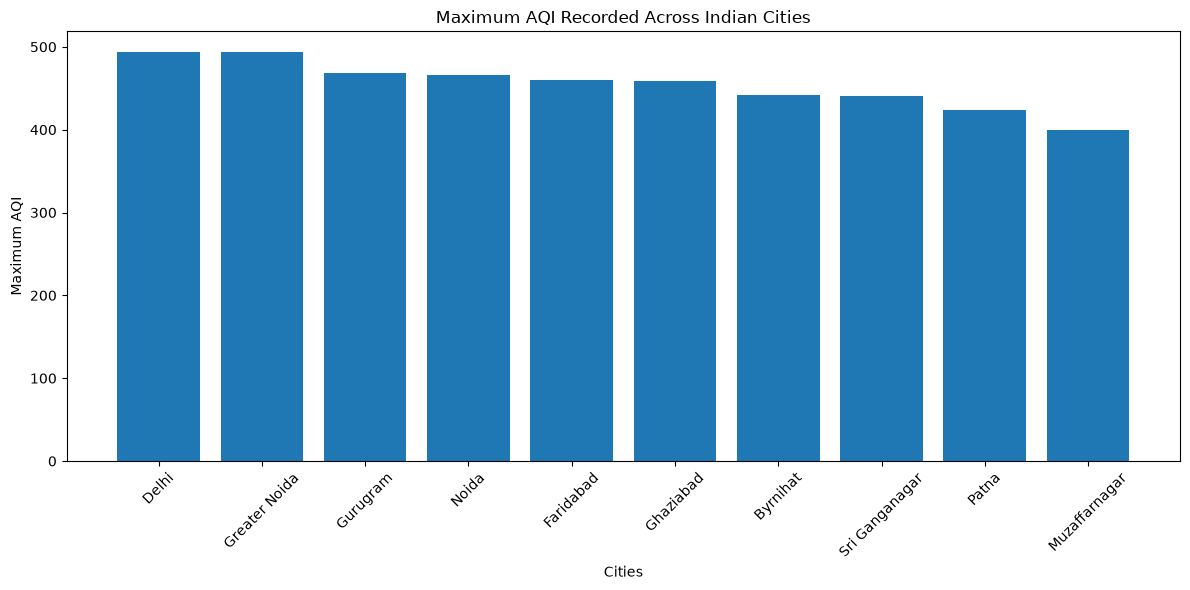

In [19]:
plt.figure(figsize=(12, 6))

plt.bar(city_aqi_sorted.index, city_aqi_sorted.values)

plt.title("Maximum AQI Recorded Across Indian Cities")
plt.xlabel("Cities")
plt.ylabel("Maximum AQI")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

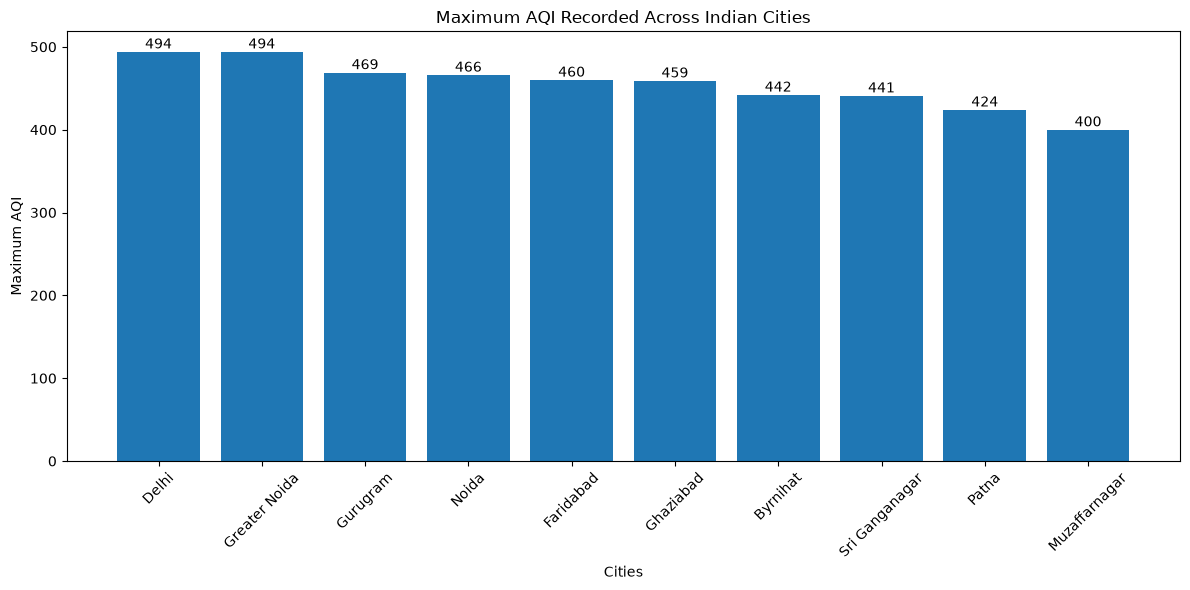

In [20]:
plt.figure(figsize=(12, 6))

bars = plt.bar(
    city_aqi_sorted.index,
    city_aqi_sorted.values
)

plt.title("Maximum AQI Recorded Across Indian Cities")
plt.xlabel("Cities")
plt.ylabel("Maximum AQI")

plt.xticks(rotation=45)

# Display AQI values above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{height:.0f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Calculate average AQI by year

In [21]:
yearly_aqi = clean_df.groupby("Year")["Maximum AQI value"].mean()

yearly_aqi

Year
2022    394.880000
2023    384.076923
2024    363.225000
2025    334.425000
2026    344.900000
Name: Maximum AQI value, dtype: float64

In [22]:
yearly_aqi = yearly_aqi.round(2)

yearly_aqi

Year
2022    394.88
2023    384.08
2024    363.22
2025    334.42
2026    344.90
Name: Maximum AQI value, dtype: float64

In [23]:
#it rounds off the decimal to 2 digits

In [24]:
yearly_aqi = clean_df.groupby("Year")["Maximum AQI value"].mean()

yearly_aqi = yearly_aqi.round(2)

yearly_aqi

Year
2022    394.88
2023    384.08
2024    363.22
2025    334.42
2026    344.90
Name: Maximum AQI value, dtype: float64

In [25]:
clean_df.groupby("Year")["Maximum AQI value"].count()

Year
2022    25
2023    39
2024    40
2025    40
2026    10
Name: Maximum AQI value, dtype: int64

Now let's visualise the yearly averages using a line chart.

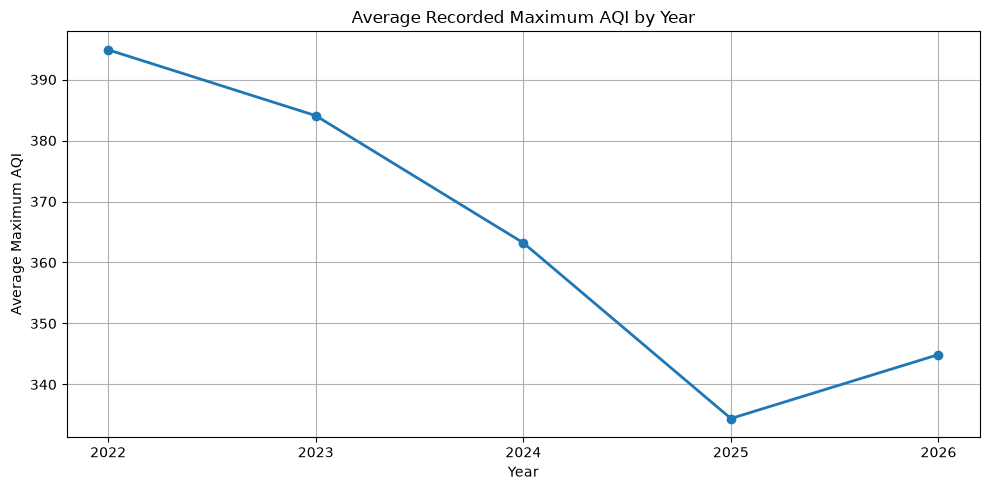

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_aqi.index,
    yearly_aqi.values,
    marker="o",
    linewidth=2
)

plt.title("Average Recorded Maximum AQI by Year")
plt.xlabel("Year")
plt.ylabel("Average Maximum AQI")

plt.xticks(yearly_aqi.index)

plt.grid(True)
plt.tight_layout()

plt.show()

Analyse pollution by month

In [27]:
monthly_aqi = clean_df.groupby("Month")["Maximum AQI value"].mean()

monthly_aqi.round(2)

Month
Dec    375.62
Jan    370.77
Nov    393.97
Oct    319.11
Name: Maximum AQI value, dtype: float64

Arrange months chronologically

In [28]:
month_order = ["Oct", "Nov", "Dec", "Jan"]

monthly_aqi = monthly_aqi.reindex(month_order)

monthly_aqi.round(2)

Month
Oct    319.11
Nov    393.97
Dec    375.62
Jan    370.77
Name: Maximum AQI value, dtype: float64

Check monthly observation counts

In [29]:
monthly_count = clean_df.groupby("Month")["Maximum AQI value"].count()

monthly_count = monthly_count.reindex(month_order)

monthly_count

Month
Oct    38
Nov    38
Dec    39
Jan    39
Name: Maximum AQI value, dtype: int64

Let's create a bar chart showing the average recorded maximum AQI for each month

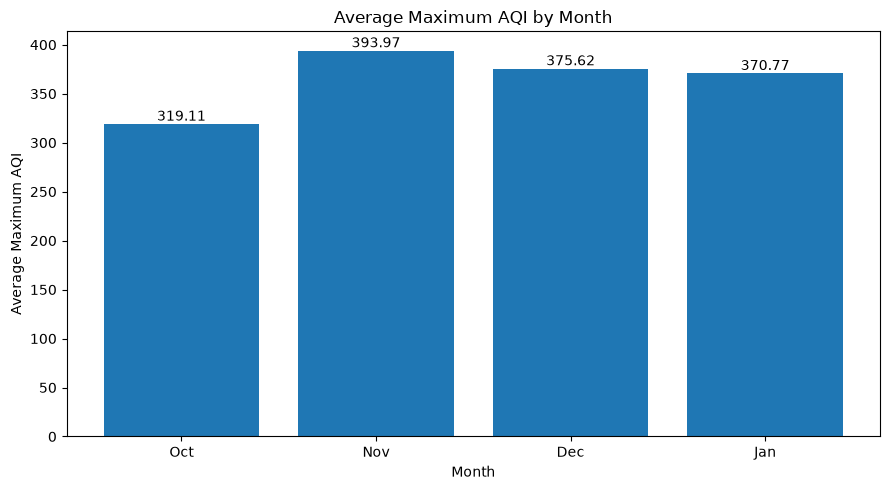

In [30]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    monthly_aqi.index,
    monthly_aqi.values
)

plt.title("Average Maximum AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average Maximum AQI")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

Compare cities across years

In [31]:
city_year_aqi = clean_df.pivot_table(
    index="City",
    columns="Year",
    values="Maximum AQI value",
    aggfunc="mean"
)

city_year_aqi.round(2)

Year,2022,2023,2024,2025,2026
City,,,,,
Byrnihat,413.00,372.00,332.50,225.50,181.0
Delhi,419.00,427.00,439.00,414.75,440.0
Faridabad,404.33,395.75,323.75,276.25,262.0
Ghaziabad,391.00,373.75,389.25,398.00,458.0
Greater Noida,417.33,422.25,371.25,391.25,402.0
Gurugram,396.33,351.50,382.25,357.50,394.0
Muzaffarnagar,366.33,357.00,331.25,336.50,322.0
Noida,393.67,398.25,393.25,407.00,430.0
Patna,365.00,344.25,309.75,242.50,236.0


Create a heatmap
Now let's turn this pivot table into a heatmap.

A heatmap uses different shades of colour to make higher and lower values easier to identify

In [32]:
import seaborn as sns

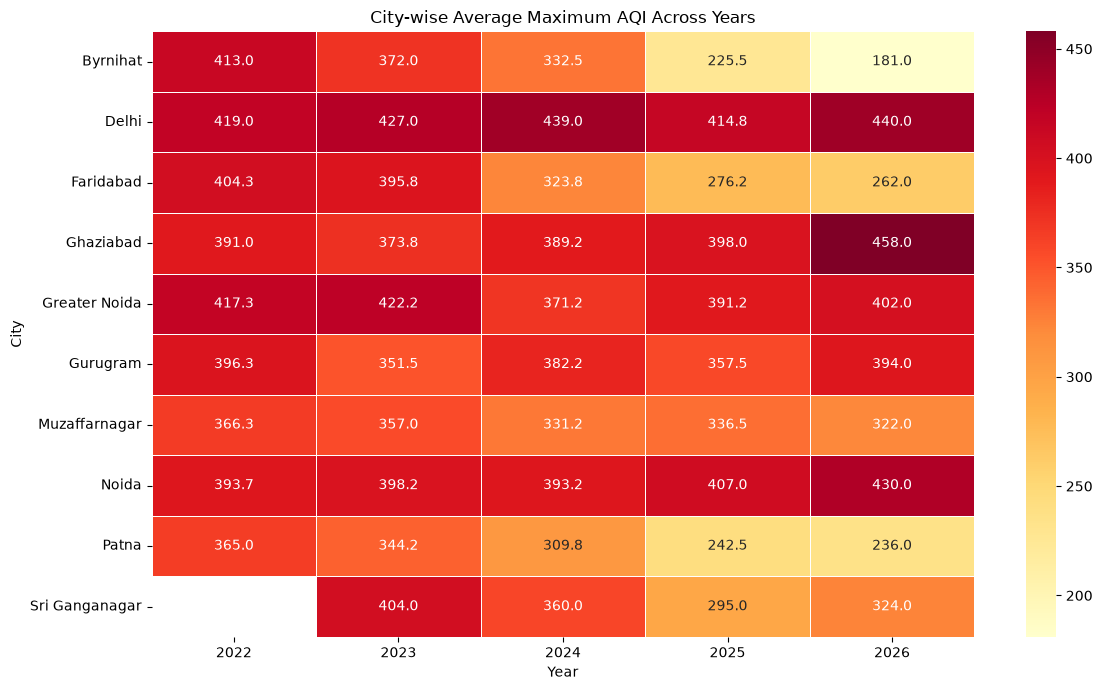

In [33]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    city_year_aqi,
    annot=True,
    cmap="YlOrRd",
    fmt=".1f",
    linewidths=0.5
)

plt.title("City-wise Average Maximum AQI Across Years")
plt.xlabel("Year")
plt.ylabel("City")

plt.tight_layout()
plt.show()

Find the average AQI for each city

In [34]:
city_avg_aqi = clean_df.groupby("City")["Maximum AQI value"].mean()

city_avg_aqi = city_avg_aqi.sort_values(ascending=False)

city_avg_aqi.round(2)

City
Delhi             426.25
Noida             400.31
Greater Noida     399.56
Ghaziabad         392.19
Gurugram          371.75
Sri Ganganagar    346.33
Muzaffarnagar     345.00
Faridabad         341.12
Byrnihat          308.14
Patna             307.31
Name: Maximum AQI value, dtype: float64

Create a city ranking chart

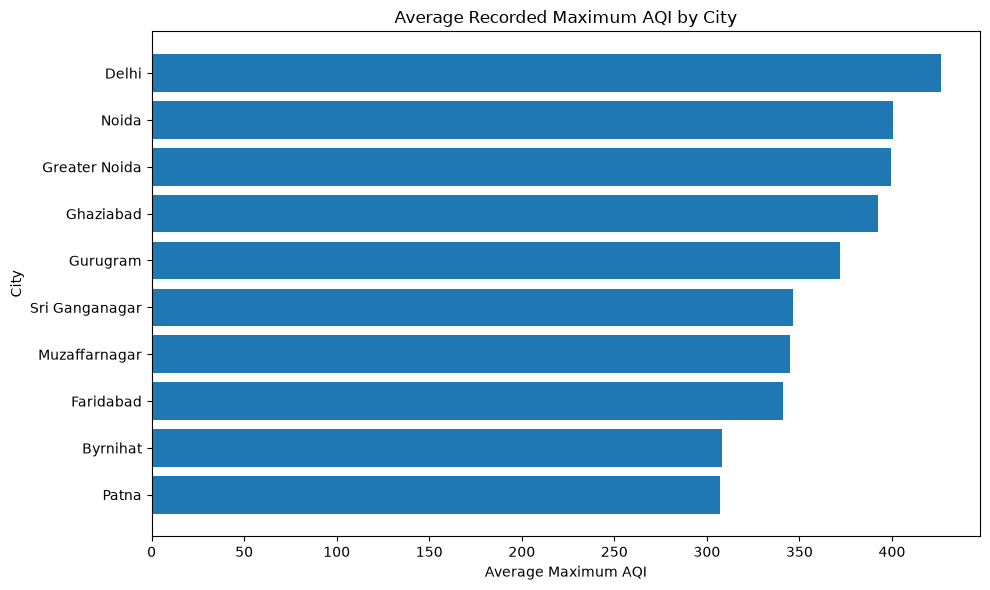

In [35]:
plt.figure(figsize=(10, 6))

plt.barh(
    city_avg_aqi.index,
    city_avg_aqi.values
)

plt.title("Average Recorded Maximum AQI by City")
plt.xlabel("Average Maximum AQI")
plt.ylabel("City")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [36]:
city_count = clean_df.groupby("City")["Maximum AQI value"].count()

city_count.sort_values(ascending=False)

City
Delhi             16
Faridabad         16
Muzaffarnagar     16
Ghaziabad         16
Greater Noida     16
Gurugram          16
Patna             16
Noida             16
Byrnihat          14
Sri Ganganagar    12
Name: Maximum AQI value, dtype: int64

## 5. AQI Category Analysis

The recorded maximum AQI values were classified into six categories: Good, Satisfactory, Moderate, Poor, Very Poor, and Severe.

This analysis helps identify the pollution severity across the selected cities and examine how frequently observations fell into the Severe category.

In [37]:
bins = [-1, 50, 100, 200, 300, 400, 500]

labels = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

clean_df["AQI Category"] = pd.cut(
    clean_df["Maximum AQI value"],
    bins=bins,
    labels=labels
)

clean_df.head()

,Sl. No.,State/UT,City,Year,Month,Day of Month on which Highest AQI Observed,Maximum AQI value,AQI Category
0,1.i,Bihar,Patna,2022,Oct,29.0,276.0,Poor
1,1.ii,Bihar,Patna,2022,Nov,30.0,395.0,Very Poor
2,1.iii,Bihar,Patna,2022,Dec,30.0,424.0,Severe
3,1.iv,Bihar,Patna,2023,Jan,1.0,414.0,Severe
4,1.v,Bihar,Patna,2023,Oct,31.0,232.0,Poor


In [38]:
clean_df["AQI Category"].value_counts()

AQI Category
Very Poor       77
Severe          49
Poor            25
Moderate         3
Good             0
Satisfactory     0
Name: count, dtype: int64

Create an AQI category distribution chart
Let's visualise these results.

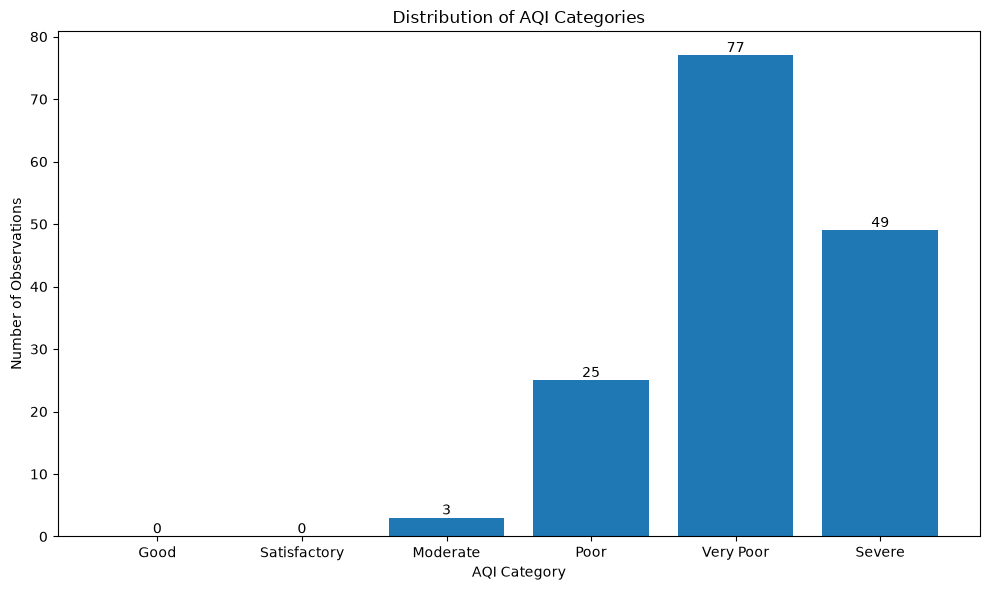

In [39]:
category_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

category_count = (
    clean_df["AQI Category"]
    .value_counts()
    .reindex(category_order, fill_value=0)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    category_count.index,
    category_count.values
)

plt.title("Distribution of AQI Categories")
plt.xlabel("AQI Category")
plt.ylabel("Number of Observations")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [40]:
severe_by_city = clean_df[
    clean_df["AQI Category"] == "Severe"
].groupby("City").size()

severe_by_city = severe_by_city.sort_values(
    ascending=False
)

severe_by_city

City
Delhi             11
Greater Noida      8
Ghaziabad          8
Noida              8
Byrnihat           3
Faridabad          3
Gurugram           3
Sri Ganganagar     3
Patna              2
dtype: int64

In [41]:
severe_percentage = (
    severe_by_city / city_count * 100
).fillna(0)

severe_percentage = severe_percentage.sort_values(
    ascending=False
)

severe_percentage.round(2)

City
Delhi             68.75
Ghaziabad         50.00
Noida             50.00
Greater Noida     50.00
Sri Ganganagar    25.00
Byrnihat          21.43
Gurugram          18.75
Faridabad         18.75
Patna             12.50
Muzaffarnagar      0.00
dtype: float64

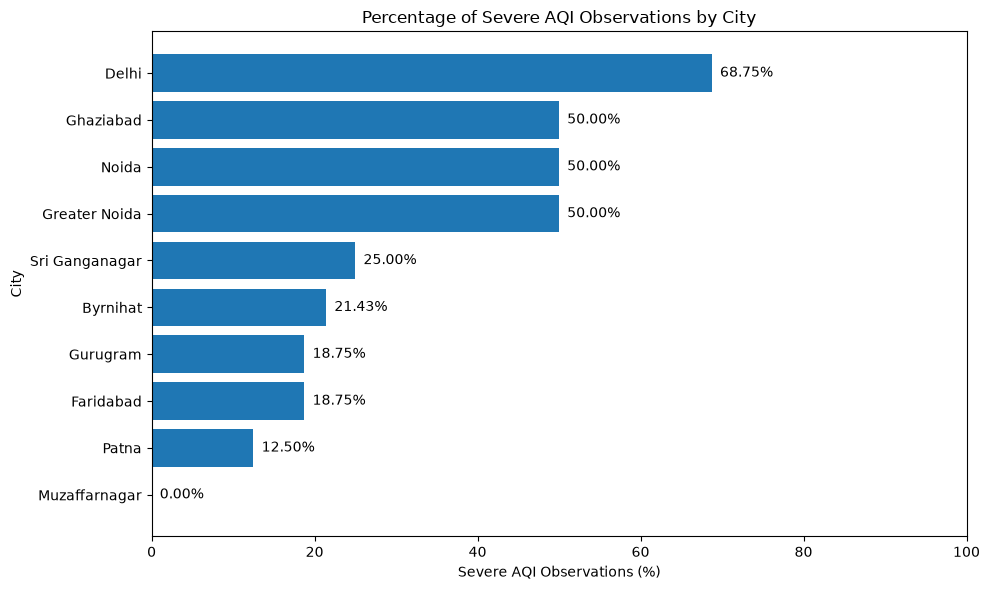

In [42]:
plt.figure(figsize=(10, 6))

bars = plt.barh(
    severe_percentage.index,
    severe_percentage.values
)

plt.title("Percentage of Severe AQI Observations by City")
plt.xlabel("Severe AQI Observations (%)")
plt.ylabel("City")

plt.gca().invert_yaxis()
plt.xlim(0, 100)

for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 1,
        bar.get_y() + bar.get_height()/2,
        f"{width:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

Save your cleaned dataset
Currently, your cleaned data exists in your notebook's memory. We need to save it as a CSV file so you can reuse it later without repeating the cleaning process.

In [43]:
clean_df.to_csv(
    "../data/cleaned_aqi_data.csv",
    index=False
)

## 6. Key Findings and Conclusion

### Key Findings

1. Delhi recorded the highest maximum AQI value of 494.
2. Delhi had the highest average recorded maximum AQI among the selected cities.
3. November had the highest monthly average recorded maximum AQI.
4. The yearly average of recorded maximum AQI decreased from 2022 to 2025, although 2026 data covers January only.
5. Out of 154 valid observations, 77 were classified as Very Poor and 49 as Severe.
6. Delhi had the highest number of Severe AQI observations.

### Conclusion

This project analysed air quality patterns across 10 selected Indian cities using Python, Pandas, Matplotlib, and Seaborn.

The analysis revealed that several observations fell into the Very Poor and Severe AQI categories, highlighting significant pollution concerns in the selected cities.

The project also provided practical experience in data cleaning, exploratory data analysis, data visualisation, and interpreting real-world datasets.

### Limitations

- The dataset covers only 10 selected cities, not all of India.
- The observations cover October, November, December, and January.
- The 2026 data contains January observations only.
- The analysis uses recorded monthly maximum AQI values, not daily or annual average AQI.